# Anomaly detection with anomalib

[anomalib](https://github.com/open-edge-platform/anomalib) is a library of anomaly detection models for images.
This notebook uses it on the same dataset as `AssignmentTemplate.ipynb`: train on normal digits only,
then score how anomalous each image is.

The model is **PatchCore** ([Roth et al. 2022](https://arxiv.org/abs/2106.08265)). It does not train a network.
Instead, it passes the normal training images through a CNN pre-trained on ImageNet, and stores the features of
their image patches in a *memory bank*. A new image is anomalous if some of its patches are far from every
patch in the memory bank: the anomaly score is the largest of these distances.

To keep this example quick, PatchCore only sees 2,000 of the training images, upscaled to 64x64 pixels.

In [4]:
import os
import logging
import warnings

# Hide the progress bar of PatchCore's memory bank sampling.
os.environ['TQDM_DISABLE'] = '1'
warnings.filterwarnings('ignore', category=FutureWarning)
warnings.filterwarnings('ignore', category=UserWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
%config InlineBackend.figure_format = 'retina'

import lightning as L
from anomalib.data import Folder, PredictDataset
from anomalib.engine import Engine
from anomalib.models import Patchcore

# Hide informational messages of anomalib and PyTorch Lightning
# (after importing them, because importing them sets up their loggers).
for name in list(logging.root.manager.loggerDict):
    if name.startswith(('lightning', 'anomalib')):
        logging.getLogger(name).setLevel(logging.ERROR)

In [6]:
# The same dataset as in AssignmentTemplate.ipynb
dataset_id = '20261029-062502_c4806367139f99116fb0e9005efb1aea'
prefix = f's3://danylo-ucla/app/storage/mnist/jobs/transform_repack/{dataset_id}'

# Normal images only.
train_X = pd.read_parquet(f'{prefix}/train_x.parquet')

# 75% anomalies, with labels.
validate_X = pd.read_parquet(f'{prefix}/validate_x.parquet')
validate_y = pd.read_parquet(f'{prefix}/validate_y.parquet')
test_X = pd.read_parquet(f'{prefix}/test_x.parquet')
test_y = pd.read_parquet(f'{prefix}/test_y.parquet')

## Images on disk

anomalib reads datasets from folders of image files, so the images are saved as PNG files, named by their row
in the dataframe. The `Folder` dataset below expects three folders: normal images for training,
and normal and abnormal images for evaluation (here, from the validate dataframe).

In [7]:
from pathlib import Path
from PIL import Image

root = Path('anomalib_dataset')


def write_images(X: pd.DataFrame, directory: str):
    directory = root / directory
    directory.mkdir(parents=True, exist_ok=True)
    for row, pixels in zip(X.index, X.values):
        image = Image.fromarray((pixels.reshape(28, 28) * 255).round().astype(np.uint8))
        image.save(directory / f'{row:05d}.png')


validate_normal = (validate_y['is_anomaly'] == 0).values

write_images(train_X.sample(2000, random_state=0), 'train')
write_images(validate_X[validate_normal], 'validate/normal')
write_images(validate_X[~validate_normal], 'validate/abnormal')
write_images(test_X, 'test')

In [8]:
datamodule = Folder(
    name='mnist',
    root=root,
    normal_dir='train',
    normal_test_dir='validate/normal',
    abnormal_dir='validate/abnormal',
    # Use the validate images for both validation and testing.
    val_split_mode='same_as_test',
    train_batch_size=256,
    eval_batch_size=256,
    num_workers=4,
)

## Model

anomalib models are PyTorch Lightning modules, trained by anomalib's `Engine` (a Lightning `Trainer`).
Other models can be swapped in with the same code, e.g. `Padim`, `EfficientAd`, `Fastflow` or `ReverseDistillation`.

- The *pre-processor* resizes the images to 64x64 (the default is 256x256, larger than needed for 28x28 images)
  and normalizes them as the ImageNet CNN expects.
- `coreset_sampling_ratio=0.01` keeps 1% of the training patches in the memory bank, chosen to cover the others
  as well as possible. More patches is slower but can be more accurate.
- PatchCore's "training" is a single pass over the training images, to fill the memory bank.

In [9]:
L.seed_everything(11)

model = Patchcore(
    backbone='wide_resnet50_2',
    layers=['layer2', 'layer3'],
    coreset_sampling_ratio=0.01,
    pre_processor=Patchcore.configure_pre_processor(image_size=(64, 64)),
    # Skip saving an image of every prediction.
    visualizer=False,
)

engine = Engine(default_root_dir='anomalib_results', logger=False, enable_progress_bar=False, enable_model_summary=False)
engine.fit(model=model, datamodule=datamodule)

model.safetensors: reconstructing file:   0%|          |  0.00B /  276MB            

model.safetensors: downloading bytes:           |  0.00B            

In [10]:
# Evaluates the model on the validate images: image_AUROC is the AUC used for grading the assignment.
engine.test(model=model, datamodule=datamodule, verbose=False)

[{'image_AUROC': 0.9599332213401794, 'image_F1Score': 0.9391898512840271}]

## Anomaly scores

`engine.predict` returns batches of predictions: an anomaly score per image (`pred_score`), and an anomaly map
per image (`anomaly_map`), i.e. how anomalous each pixel location is. The image file names give the row of each
prediction in the dataframe.

In [11]:
from torch.utils.data import DataLoader
from sklearn.metrics import roc_auc_score


def predict(directory: str):
    dataset = PredictDataset(root / directory)
    loader = DataLoader(dataset, batch_size=256, num_workers=4, collate_fn=dataset.collate_fn)
    batches = engine.predict(model=model, dataloaders=loader)

    rows = [int(Path(path).stem) for batch in batches for path in batch.image_path]
    scores = np.concatenate([batch.pred_score.cpu().numpy().ravel() for batch in batches])
    maps = np.concatenate([batch.anomaly_map.cpu().numpy().reshape(-1, 64, 64) for batch in batches])

    order = np.argsort(rows)
    return scores[order], maps[order]


test_scores, test_maps = predict('test')
roc_auc_score(test_y['is_anomaly'], test_scores)

0.9544384217687075

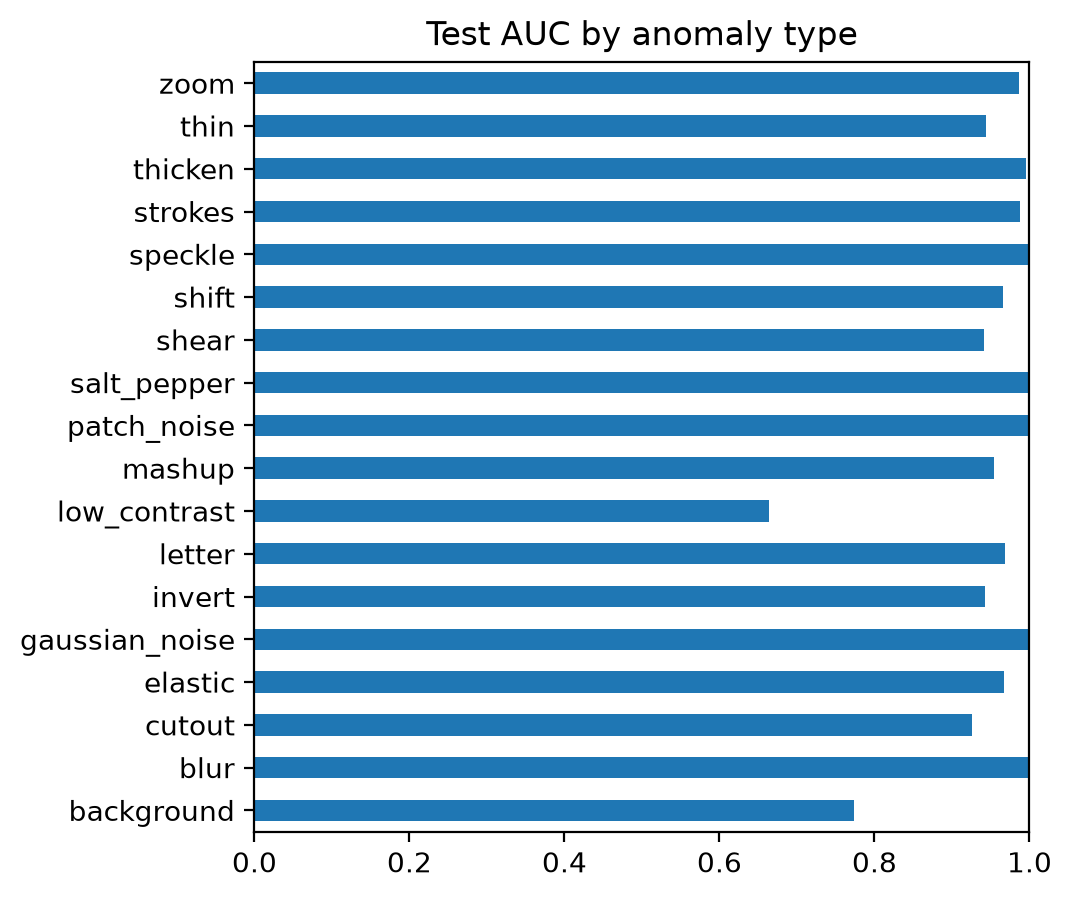

In [12]:
# AUC of each anomaly type: images of that type against all normal images.
normal = (test_y['is_anomaly'] == 0).values
auc_by_type = pd.Series({
    anomaly_type: roc_auc_score(test_y['is_anomaly'][normal | mask], test_scores[normal | mask])
    for anomaly_type in sorted(test_y.loc[~normal, 'anomaly_type'].unique())
    for mask in [(test_y['anomaly_type'] == anomaly_type).values]
})
auc_by_type.plot.barh(title='Test AUC by anomaly type', xlim=(0, 1), figsize=(5, 5))
plt.show()

## Anomaly maps

The anomaly map shows *where* the model finds an image anomalous (brighter = more anomalous).
Below: a normal image and an example of several anomaly types from the test dataframe, with their scores
(normalized by anomalib so that 0.5 is its threshold between normal and anomalous).
The maps are coarse: at 64x64 pixels, the CNN features that PatchCore compares form an 8x8 grid.

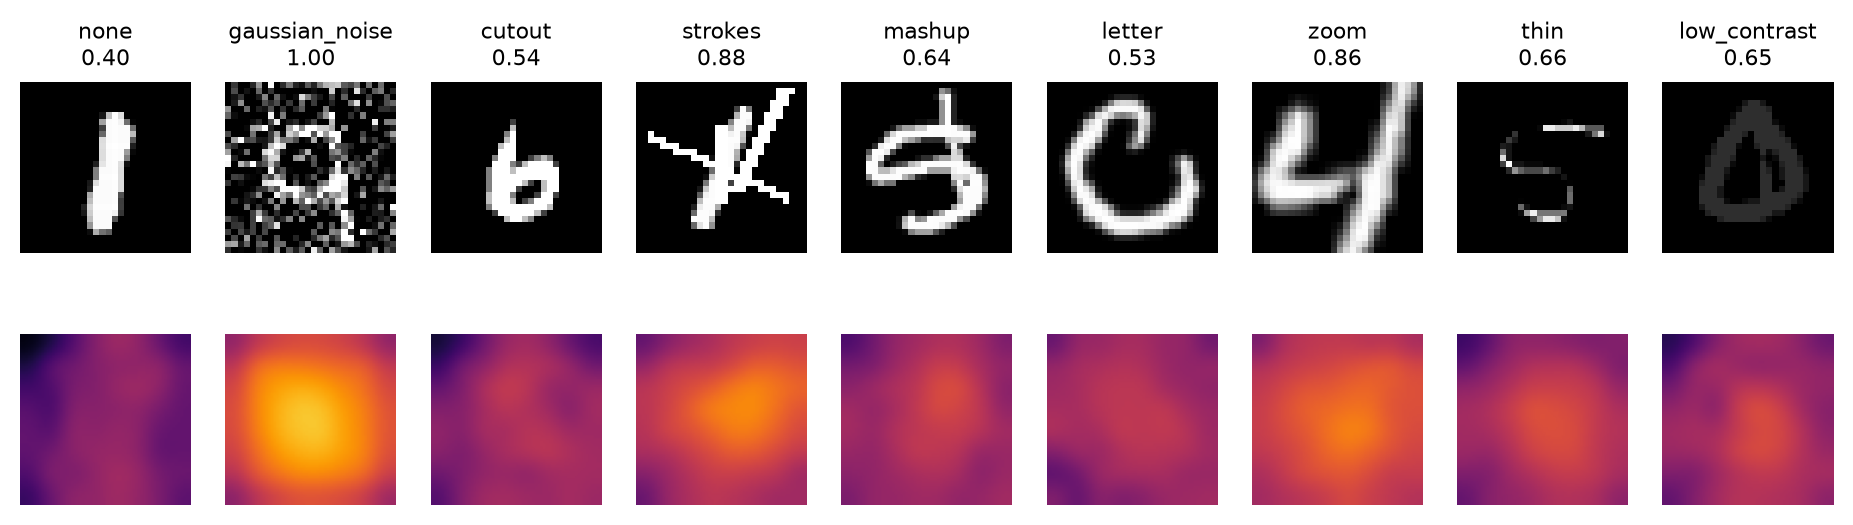

In [13]:
examples = ['none', 'gaussian_noise', 'cutout', 'strokes', 'mashup', 'letter', 'zoom', 'thin', 'low_contrast']
rows = [np.flatnonzero(test_y['anomaly_type'] == t)[0] for t in examples]

fig, axes = plt.subplots(2, len(examples), figsize=(len(examples) * 1.3, 3))
for c, (anomaly_type, row) in enumerate(zip(examples, rows)):
    axes[0, c].imshow(test_X.values[row].reshape(28, 28), cmap='gray', vmin=0, vmax=1)
    axes[0, c].set_title(f'{anomaly_type}\n{test_scores[row]:.2f}', fontsize=8)
    axes[1, c].imshow(test_maps[row], cmap='inferno', vmin=test_maps.min(), vmax=test_maps.max())
for ax in axes.flat:
    ax.axis('off')
plt.show()